MODULO 3 CAPITOLO 5 VIDEO 6 COMBINAZIONE REGRESSIONI IN PYTHON 

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression

In [4]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y= pd.Series(data.target, name= "target")
X.head()


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [5]:
y.describe()


count    569.000000
mean       0.627417
std        0.483918
min        0.000000
25%        0.000000
50%        1.000000
75%        1.000000
max        1.000000
Name: target, dtype: float64

In [8]:
#selezioniamo una singola features (mean radius), applicargli la regressione lineare e poi quella logistica

X_sel = X[["mean radius"]]

lin_reg = LinearRegression()
lin_reg.fit(X_sel, y)

y_lin = lin_reg.predict(X_sel)


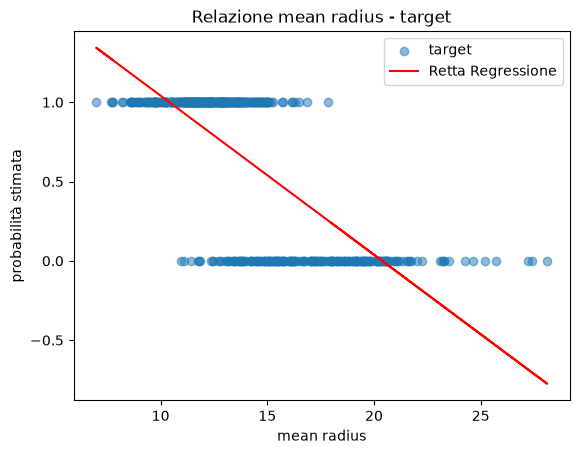

In [9]:
plt.scatter(X_sel,y, label="target", alpha = 0.5)
plt.plot(X_sel, y_lin, color="red", label="Retta Regressione")
plt.xlabel("mean radius")
plt.ylabel("probabilità stimata")
plt.title("Relazione mean radius - target")
plt.legend()
plt.show()


In [11]:
X_new= X.copy()
X_new["lin_pred"] = y_lin

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_new, y)

y_pred = log_reg.predict(X_new)
accuracy = (y_pred == y).mean()
print(f"Accuracy: {accuracy * 100:.2f}%")



Accuracy: 95.78%


c:\Users\Utente\AppData\Local\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [13]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_new)

log_reg_scaled = LogisticRegression(max_iter=1000, random_state=42)
log_reg_scaled.fit(X_scaled,y)

y_pred_scaled = log_reg_scaled.predict(X_scaled)

accuracy_scaled = (y_pred_scaled == y ).mean()
print(f"Accuracy:{accuracy_scaled * 100:.2f}%")




Accuracy:98.77%


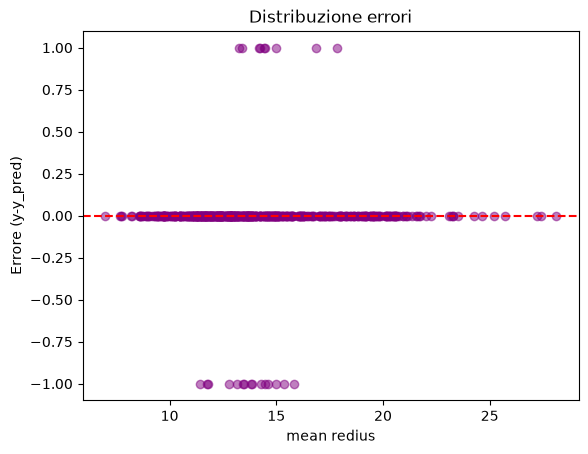

In [15]:
#scatterplot della distribuzione degli errori 

plt.scatter(X_sel, y-y_pred, alpha= 0.5, color = "purple")
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("mean redius")
plt.ylabel("Errore (y-y_pred)")
plt.title("Distribuzione errori")
plt.show()


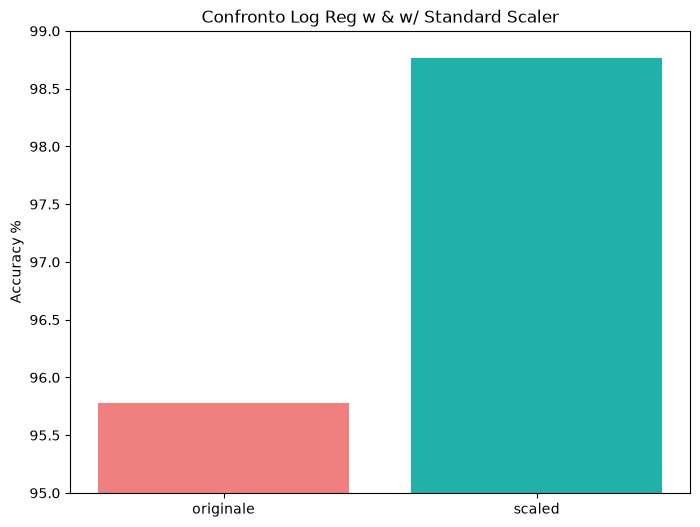

In [16]:
#grafico a barre per vedere differenza con e senza scalatura

plt.figure(figsize=(8,6))
plt.bar(
    ["originale", "scaled"],
    [accuracy * 100, accuracy_scaled * 100],
    color=["lightcoral", "lightseagreen"]
)
plt.ylabel("Accuracy %")
plt.title("Confronto Log Reg w & w/ Standard Scaler")
plt.ylim(95,99)
plt.show()